In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
df_qrf = pd.read_csv('../results.csv')
df = pd.read_csv('../results-lstm.csv')

df_qrf['Model']='QRF'
df['Model']='LSTM-AE'

df = pd.concat([df, df_qrf])
df = df.rename(
    columns={
        'picp_delta_cog': r'$PICP_{\Delta COG}$',
        'pinaw_delta_cog': r'$PINAW_{\Delta COG}$',
        'picp_delta_dif': r'$PICP_{\Delta DIF}$',
        'pinaw_delta_dif': r'$PINAW_{\Delta DIF}$',
    }
)

df

,Unnamed: 0,$PICP_{\Delta COG}$,$PINAW_{\Delta COG}$,$PICP_{\Delta DIF}$,$PINAW_{\Delta DIF}$,Model
0,0,0.958012,0.285649,0.956872,0.148119,LSTM-AE
1,1,0.949572,0.271817,0.952904,0.145208,LSTM-AE
2,2,0.958775,0.289908,0.949980,0.143640,LSTM-AE
3,3,0.954875,0.282048,0.950264,0.143758,LSTM-AE
4,4,0.952430,0.279068,0.952821,0.145428,LSTM-AE
0,0,0.938896,0.270390,0.935331,0.138216,QRF
1,1,0.938116,0.268486,0.934487,0.137586,QRF
2,2,0.938830,0.268810,0.934815,0.137879,QRF
3,3,0.937660,0.267390,0.933695,0.137294,QRF
4,4,0.936388,0.266920,0.933108,0.136888,QRF


In [3]:
import seaborn as sns

In [4]:
df_ = df.melt(
    id_vars=['Unnamed: 0', 'Model'],
    value_name='Metric value'
)

df_['Metric'] = 'PINAW'
df_.loc[df_.apply(lambda x: 'PICP' in x['variable'], axis='columns'), 'Metric'] = 'PICP'
df_['Variable'] = r'$\Delta COG$'
df_.loc[df_.apply(lambda x: r'\Delta DIF' in x['variable'], axis='columns'), 'Variable'] = r'$\Delta DIF$'

In [5]:
df_

,Unnamed: 0,Model,variable,Metric value,Metric,Variable
0,0,LSTM-AE,$PICP_{\Delta COG}$,0.958012,PICP,$\Delta COG$
1,1,LSTM-AE,$PICP_{\Delta COG}$,0.949572,PICP,$\Delta COG$
2,2,LSTM-AE,$PICP_{\Delta COG}$,0.958775,PICP,$\Delta COG$
3,3,LSTM-AE,$PICP_{\Delta COG}$,0.954875,PICP,$\Delta COG$
4,4,LSTM-AE,$PICP_{\Delta COG}$,0.952430,PICP,$\Delta COG$
5,0,QRF,$PICP_{\Delta COG}$,0.938896,PICP,$\Delta COG$
6,1,QRF,$PICP_{\Delta COG}$,0.938116,PICP,$\Delta COG$
7,2,QRF,$PICP_{\Delta COG}$,0.938830,PICP,$\Delta COG$
8,3,QRF,$PICP_{\Delta COG}$,0.937660,PICP,$\Delta COG$
9,4,QRF,$PICP_{\Delta COG}$,0.936388,PICP,$\Delta COG$


In [6]:
plt.style.use('bmh')
plt.rcParams['axes.facecolor'] = 'white'

/home/lukas/Dokumentai/studijos/kursinis-projektas/.venv/lib/python3.12/site-packages/seaborn/axisgrid.py:123: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  self._figure.tight_layout(*args, **kwargs)
/home/lukas/Dokumentai/studijos/kursinis-projektas/.venv/lib/python3.12/site-packages/seaborn/axisgrid.py:123: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  self._figure.tight_layout(*args, **kwargs)
/home/lukas/Dokumentai/studijos/kursinis-projektas/.venv/lib/python3.12/site-packages/seaborn/axisgrid.py:123: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  self._figure.tight_layout(*args, **kwargs)
/tmp/ipykernel_7491/2313422594.py:19: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


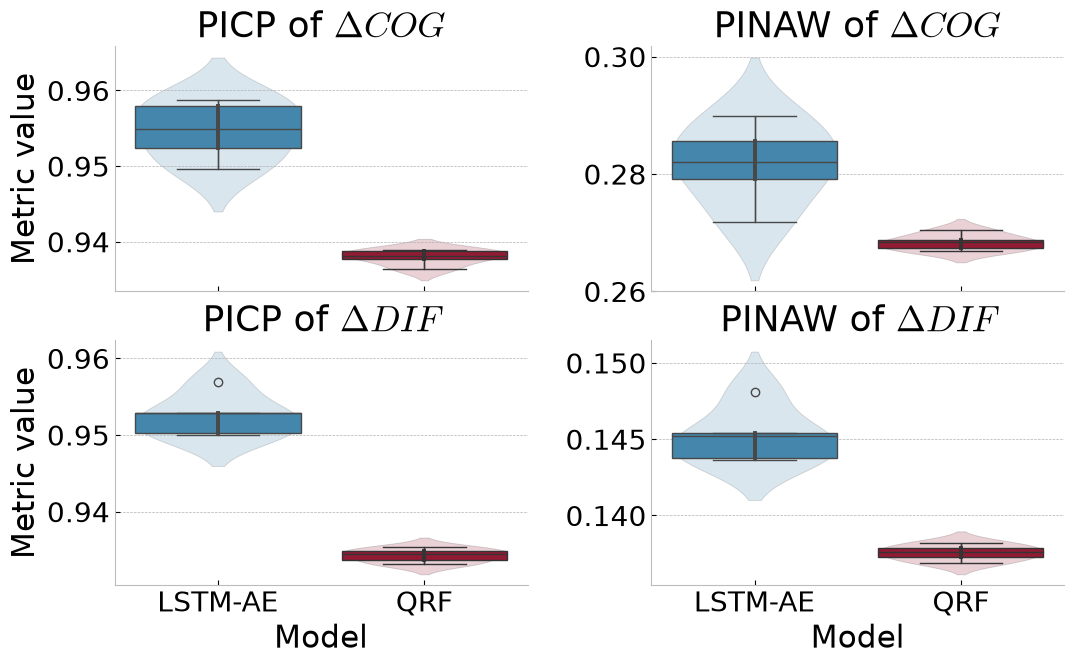

In [9]:
# fig,axs = plt.subplots(nrows=2, ncols=2, figsize=(10,8))

g = sns.FacetGrid(df_, col="Metric",  row="Variable", sharey=False, hue='Model', height=3.5, aspect=1.75, gridspec_kws={'wspace': 0.3})
g.map_dataframe(sns.boxplot, **{
    'x': 'Model',
    'y': 'Metric value',
})
g.map_dataframe(sns.violinplot, **{
    'x': 'Model',
    'y': 'Metric value',
    'alpha': 0.2
})

g.tick_params(axis='both', labelsize=20)
g.set_ylabels(size=22)
g.set_xlabels(size=22)
g.set_titles('{col_name} of {row_name}', size=26)

plt.tight_layout()
plt.savefig('metrics-pi.png', dpi=1000)